# Bài 3 - Neural Network phân lớp MNIST bằng 10-fold Cross Validation

**Sinh viên:** Nguyễn Đức Vinh  
**MSSV:** 6451071087

Sử dụng KFold(k=10), huấn luyện 5 epoch cho mỗi fold, lưu mô hình và chọn mô hình có validation accuracy cao nhất.

> Chạy lần lượt các cell từ trên xuống dưới trong Google Colab. Mỗi notebook là một bài độc lập.

## 1. Thư viện và thông tin sinh viên

In [9]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.model_selection import KFold
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix)

print("Nguyễn Đức Vinh - MSSV: 6451071087")
tf.keras.utils.set_random_seed(42)

Nguyễn Đức Vinh - MSSV: 6451071087


## 2. Đọc dữ liệu và chuẩn hóa (câu a, b, c)

In [10]:
print("Nguyễn Đức Vinh - MSSV: 6451071087")
(train_images, train_labels), (test_images, test_labels) = tf.keras.datasets.mnist.load_data()
print("Train:", train_images.shape, train_labels.shape)
print("Test:", test_images.shape, test_labels.shape)
train_images = train_images.astype("float32") / 255.0
test_images = test_images.astype("float32") / 255.0

Nguyễn Đức Vinh - MSSV: 6451071087
Train: (60000, 28, 28) (60000,)
Test: (10000, 28, 28) (10000,)


## 3. Hàm create_model (câu d)

In [11]:
print("Nguyễn Đức Vinh - MSSV: 6451071087")
def create_model():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(10, activation="softmax")
    ])
    model.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

Nguyễn Đức Vinh - MSSV: 6451071087


## 4. Huấn luyện 10-fold cross validation và lưu mô hình (câu e)

In [12]:
print("Nguyễn Đức Vinh - MSSV: 6451071087")
kfold = KFold(n_splits=10, shuffle=True, random_state=42)
accuracy_per_fold = []
loss_per_fold = []
models = []
fold_histories = []
model_dir = "/content/6451071087_LAB3_Bai3_models"
os.makedirs(model_dir, exist_ok=True)

for fold, (train_index, val_index) in enumerate(kfold.split(train_images), start=1):
    print(f"\n========== FOLD {fold}/10 ==========")
    X_train_fold = train_images[train_index]
    X_val_fold = train_images[val_index]
    y_train_fold = train_labels[train_index]
    y_val_fold = train_labels[val_index]

    tf.keras.backend.clear_session()
    model = create_model()
    history = model.fit(
        X_train_fold, y_train_fold,
        validation_data=(X_val_fold, y_val_fold),
        epochs=5,
        batch_size=32,
        verbose=1
    )
    val_loss, val_accuracy = model.evaluate(X_val_fold, y_val_fold, verbose=0)
    model.save(os.path.join(model_dir, f"fold_{fold}.keras"))
    models.append(model)
    fold_histories.append(history.history)
    loss_per_fold.append(float(val_loss))
    accuracy_per_fold.append(float(val_accuracy))
    print(f"Fold {fold}: val_loss={val_loss:.4f}, val_accuracy={val_accuracy:.4f}")

Nguyễn Đức Vinh - MSSV: 6451071087

========== FOLD 1/10 ==========
Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 18s 8ms/step - accuracy: 0.9093 - loss: 0.3161 - val_accuracy: 0.9567 - val_loss: 0.1493
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.9546 - loss: 0.1519 - val_accuracy: 0.9692 - val_loss: 0.1065
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9669 - loss: 0.1115 - val_accuracy: 0.9735 - val_loss: 0.0913
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9707 - loss: 0.0935 - val_accuracy: 0.9752 - val_loss: 0.0841
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9754 - loss: 0.0789 - val_accuracy: 0.9773 - val_loss: 0.0770
Fold 1: val_loss=0.0770, val_accuracy=0.9773

========== FOLD 2/10 ==========
Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9110 - loss: 0.3072 - val_accuracy: 0.9530 - val_loss: 0.1638
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9549 - loss:

## 5. Tính Mean và Standard Deviation (câu f)

In [13]:
print("Nguyễn Đức Vinh - MSSV: 6451071087")
print("Mean Accuracy:", np.mean(accuracy_per_fold))
print("Std Accuracy:", np.std(accuracy_per_fold))
print("Mean Loss:", np.mean(loss_per_fold))
print("Std Loss:", np.std(loss_per_fold))
for i, (acc, loss) in enumerate(zip(accuracy_per_fold, loss_per_fold), start=1):
    print(f"Fold {i:02d}: accuracy={acc:.4f}, loss={loss:.4f}")

Nguyễn Đức Vinh - MSSV: 6451071087
Mean Accuracy: 0.9731000006198883
Std Accuracy: 0.002926119874421864
Mean Loss: 0.09020643681287766
Std Loss: 0.009843588344127987
Fold 01: accuracy=0.9773, loss=0.0770
Fold 02: accuracy=0.9730, loss=0.0892
Fold 03: accuracy=0.9668, loss=0.1067
Fold 04: accuracy=0.9753, loss=0.0860
Fold 05: accuracy=0.9695, loss=0.1055
Fold 06: accuracy=0.9750, loss=0.0835
Fold 07: accuracy=0.9728, loss=0.0989
Fold 08: accuracy=0.9755, loss=0.0814
Fold 09: accuracy=0.9722, loss=0.0918
Fold 10: accuracy=0.9735, loss=0.0820


## 6. Biểu đồ Accuracy và Loss theo Fold (câu g)

Nguyễn Đức Vinh - MSSV: 6451071087


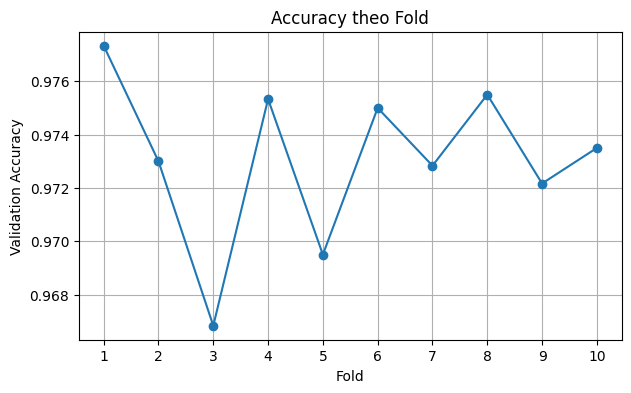

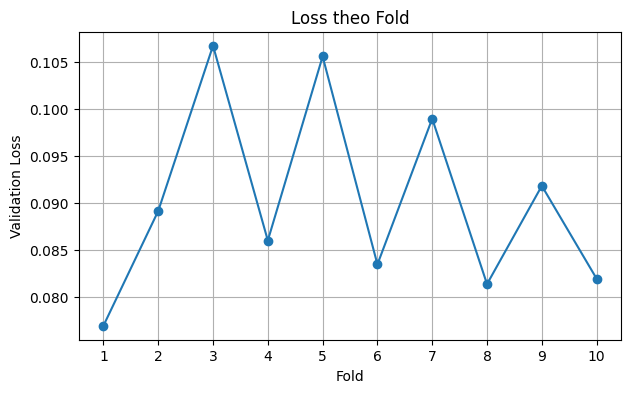

In [14]:
print("Nguyễn Đức Vinh - MSSV: 6451071087")
fold_numbers = np.arange(1, 11)
plt.figure(figsize=(7, 4))
plt.plot(fold_numbers, accuracy_per_fold, marker="o")
plt.xlabel("Fold")
plt.ylabel("Validation Accuracy")
plt.title("Accuracy theo Fold")
plt.xticks(fold_numbers)
plt.grid(True)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(fold_numbers, loss_per_fold, marker="o")
plt.xlabel("Fold")
plt.ylabel("Validation Loss")
plt.title("Loss theo Fold")
plt.xticks(fold_numbers)
plt.grid(True)
plt.show()

## 7. Chọn mô hình có Accuracy cao nhất và đánh giá tập test (câu h, i, j, k)

Nguyễn Đức Vinh - MSSV: 6451071087
Fold tốt nhất: 1
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
Test Accuracy: 0.976
              precision    recall  f1-score   support

           0     0.9730    0.9918    0.9823       980
           1     0.9808    0.9903    0.9855      1135
           2     0.9785    0.9690    0.9737      1032
           3     0.9660    0.9832    0.9745      1010
           4     0.9641    0.9857    0.9748       982
           5     0.9786    0.9731    0.9758       892
           6     0.9883    0.9708    0.9795       958
           7     0.9774    0.9689    0.9731      1028
           8     0.9701    0.9651    0.9676       974
           9     0.9838    0.9604    0.9719      1009

    accuracy                         0.9760     10000
   macro avg     0.9760    0.9758    0.9759     10000
weighted avg     0.9761    0.9760    0.9760     10000



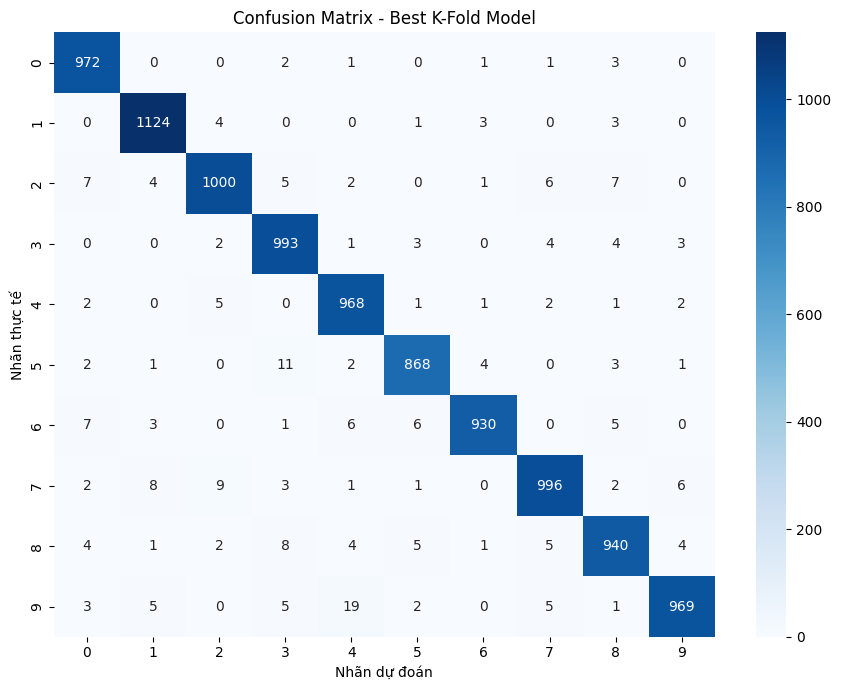

In [15]:
print("Nguyễn Đức Vinh - MSSV: 6451071087")
best_index = int(np.argmax(accuracy_per_fold))
best_model = models[best_index]
print("Fold tốt nhất:", best_index + 1)

test_prob = best_model.predict(test_images, batch_size=256, verbose=1)
test_pred = np.argmax(test_prob, axis=1)
print("Test Accuracy:", accuracy_score(test_labels, test_pred))
print(classification_report(test_labels, test_pred,
                            labels=np.arange(10), digits=4, zero_division=0))
cm = confusion_matrix(test_labels, test_pred, labels=np.arange(10))
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Nhãn dự đoán")
plt.ylabel("Nhãn thực tế")
plt.title("Confusion Matrix - Best K-Fold Model")
plt.tight_layout()
plt.show()

## 8. In 05 kết quả đầu tiên trên tập test (câu l)

Nguyễn Đức Vinh - MSSV: 6451071087


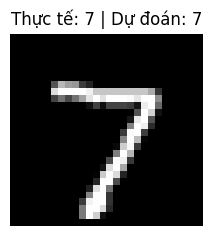

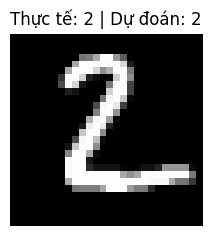

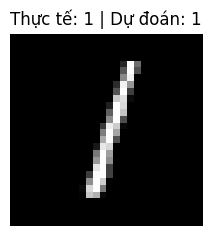

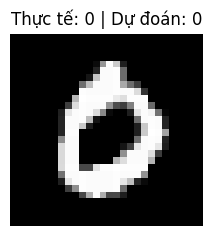

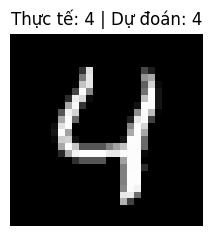

In [16]:
print("Nguyễn Đức Vinh - MSSV: 6451071087")
for index in range(5):
    predicted = int(test_pred[index])
    actual = int(test_labels[index])
    plt.figure(figsize=(2.5, 2.5))
    plt.imshow(test_images[index], cmap="gray")
    plt.title(f"Thực tế: {actual} | Dự đoán: {predicted}")
    plt.axis("off")
    plt.show()